### Installation des dépendances

Configuration adaptée du notebook `LLM setup` fourni dans le modèle de projet pour exécuter [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) et le pipeline RAG sur Google Colab.

- L'environnement Colab est configuré avec un GPU T4 et un runtime Python 3.11.
- La cellule installe les dépendances nécessaires avec `uv`, en fixant les versions de certaines bibliothèques et en ajoutant celles nécessaires au RAG.
- L'installation est ignorée lorsque PandasAI 3.0.0 et les trois bibliothèques RAG sont déjà présents. Après une première installation, un redémarrage de la session Colab est nécessaire.
- Hors Colab, l'installation est ignorée et l'environnement peut être configuré localement avec `uv sync --extra llm --extra rag`.

In [1]:
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

IN_COLAB = "google.colab" in sys.modules


def installed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None


# Skipped once the packages are installed, so this cell can be re-run after restarting the session.
if IN_COLAB and installed_version("pandasai") != "3.0.0":
    if sys.version_info[:2] != (3, 11):
        raise RuntimeError("Choose a Python 3.11 Colab runtime before installing these packages.")

    subprocess.check_call([sys.executable, "-m", "pip", "install", "uv>=0.8,<1"])

    packages = [
        "ipython>=8,<9",
        "matplotlib-inline<0.2",
        "numpy==1.26.4",
        "pandas==2.3.3",
        "transformers==5.17.0",
        "accelerate==1.15.0",
        "bitsandbytes==0.50.2",
        "peft==0.21.2",
        "sentence-transformers>=6.1.0",
        "requests",
        "pandasai==3.0.0",
    ]

    subprocess.check_call([sys.executable, "-m", "uv", "pip", "install",
                           "--python", sys.executable, *packages])
    print("Installation finished. Choose Runtime → Restart session before continuing.")

### Récupération du dépôt GitHub

Cette cellule clone le dépôt GitHub de notre équipe dans `/content/repo` afin de rendre le package `ift6758` accessible depuis Colab.

- Le clonage est effectué uniquement si le dossier cible n'existe pas déjà.
- Le dossier du dépôt est ajouté à `sys.path` pour permettre l'importation des modules Python du projet.
- Hors Colab, cette étape est ignorée.

In [79]:
import os

if IN_COLAB:
    from google.colab import userdata

    REPO = "ammou35/LNH-data-science"
    REPO_DIR = "/content/repo"

    if not os.path.exists(REPO_DIR):
        subprocess.check_call(["git", "clone", f"https://github.com/{REPO}", REPO_DIR])

    PROJECT_DIR = os.path.join(REPO_DIR, "data_science_project")
    sys.path.insert(0, PROJECT_DIR)

### Vérification de l'environnement

- Vérification de la version de Python et des principales dépendances.
- Affichage des versions utilisées pour documenter l'environnement et faciliter la reproductibilité des résultats.

In [80]:
import sys
import torch
import numpy as np
import pandas as pd
from importlib.metadata import version

if sys.version_info[:2] != (3, 11):
    raise RuntimeError("A Python 3.11 runtime is required.")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Transformers:", version("transformers"))
print("Accelerate:", version("accelerate"))
print("PandasAI:", version("pandasai"))

Python: 3.11.16
PyTorch: 2.14.0
NumPy: 1.26.4
pandas: 2.3.3
Transformers: 5.17.0
Accelerate: 1.15.0
PandasAI: 3.0.0


### Vérification du GPU

- Si un GPU est disponible, son nom est affiché.
- Sinon, un message rappelle de sélectionner un runtime GPU T4 dans les paramètres de Google Colab.

In [81]:
import torch

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("No CUDA GPU found. On Colab, select a T4 GPU runtime (Runtime → Change runtime type).")

No CUDA GPU found. On Colab, select a T4 GPU runtime (Runtime → Change runtime type).


### Chargement du modèle Qwen

- Le modèle Qwen3-4B-Instruct-2507 est chargé à l'aide de la fonction `load_model()` du package `ift6758`.
- Lors de la première exécution, environ 8 Go de poids sont téléchargés dans le cache Hugging Face.
- Le périphérique d'exécution et le type de données numériques du modèle sont affichés après le chargement.
- Une première requête sur le hockey permet de vérifier la génération de texte avec le gabarit de conversation de Qwen.

In [82]:
from ift6758.llm import load_model

model, tokenizer = load_model()
print(f"Loaded on {model.device} ({model.dtype})")

2026-10-20 05:09:52 [INFO] HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-10-20 05:09:52 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-4B-Instruct-2507/cdbee75f17c01a7cc42f958dc650907174af0554/config.json?%2FQwen%2FQwen3-4B-Instruct-2507%2Fresolve%2Fmain%2Fconfig.json=&etag=%226988f134db143052042f2bd6e0c897bc6a605189%22 "HTTP/1.1 200 OK"
2026-10-20 05:09:52 [INFO] HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-10-20 05:09:52 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-4B-Instruct-2507/cdbee75f17c01a7cc42f958dc650907174af0554/tokenizer_config.json?%2FQwen%2FQwen3-4B-Instruct-2507%2Fresolve%2Fmain%2Ftokenizer_config.json=&etag=%2251c1be0d9192e7f6e6596de71d0f07d58fbc32ac%22 "HTTP/1.1 200 OK"
2026-10-20 05:09:52 [INFO] HTTP Reques

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

2026-10-20 05:10:04 [INFO] HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-10-20 05:10:04 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-4B-Instruct-2507/cdbee75f17c01a7cc42f958dc650907174af0554/generation_config.json?%2FQwen%2FQwen3-4B-Instruct-2507%2Fresolve%2Fmain%2Fgeneration_config.json=&etag=%22432531a002c181a19de338313d2375e9d7494d7e%22 "HTTP/1.1 200 OK"
Loaded on mps:0 (torch.float16)


In [83]:
def ask_qwen(prompt, system="You are a helpful assistant.", max_new_tokens=512):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens)

    return tokenizer.decode(output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

print(ask_qwen("In one sentence, what is a hat trick in hockey?"))

In hockey, a hat trick occurs when a player scores a goal, assists on two other goals, or records a goal and two assists in the same game.


### Chargement et nettoyage des données de la NHL

Cette cellule récupère les données de la NHL de 2018 à 2020, les regroupe dans un dataframe pandas et calcule la distance des tirs au filet.

In [84]:
from IPython.display import display, Markdown, Image
from ift6758.data.nhl import download_seasons
from ift6758.data import season_to_pandas
from ift6758.visualizations.simple_viz import compute_distance

download_seasons(first=2018, last=2020)
shots = pd.concat([season_to_pandas(year) for year in range(2018, 2021)], ignore_index=True)
shots = compute_distance(shots)

display(shots.head())

2018 regular: 1271game [00:05, 233.96game/s] 
2018 playoffs: 87game [00:06, 14.22game/s]
2019 regular: 1082game [00:04, 230.35game/s]
2019 playoffs: 86game [00:07, 10.87game/s]
2020 regular: 868game [00:03, 223.48game/s] 
2020 playoffs: 84game [00:08, 10.48game/s]


,season,game_id,event_id,game_type,period,period_type,time_in_period,team,team_id,event_type,is_goal,x,y,player_name,goalie_name,shot_type,zone,empty_net,strength,distance
0,2018,2018020001,10,2,1,REG,00:29,MTL,8,shot-on-goal,False,78,-19,"{'first_name': {'default': 'Artturi'}, 'last_n...","{'first_name': {'default': 'Frederik'}, 'last_...",backhand,O,False,0,21.0
1,2018,2018020001,11,2,1,REG,00:49,TOR,10,shot-on-goal,False,-37,-10,"{'first_name': {'default': 'Morgan'}, 'last_na...","{'first_name': {'default': 'Carey'}, 'last_nam...",snap,O,False,0,52.0
2,2018,2018020001,12,2,1,REG,01:00,MTL,8,shot-on-goal,False,47,-23,"{'first_name': {'default': 'Brendan'}, 'last_n...","{'first_name': {'default': 'Frederik'}, 'last_...",wrist,O,False,0,47.0
3,2018,2018020001,18,2,1,REG,03:54,MTL,8,shot-on-goal,False,53,14,"{'first_name': {'default': 'Brendan'}, 'last_n...","{'first_name': {'default': 'Frederik'}, 'last_...",snap,O,False,0,38.0
4,2018,2018020001,20,2,1,REG,04:06,MTL,8,shot-on-goal,False,77,-2,"{'first_name': {'default': 'Mike'}, 'last_name...","{'first_name': {'default': 'Frederik'}, 'last_...",snap,O,False,0,12.0


### Calcul des résultats de référence

Cette cellule calcule les nombres de tirs, de buts et les pourcentages de buts par équipe pour la saison 2018-19. Ces résultats servent à vérifier les trois types de requêtes reprises de la démo.

In [85]:
expected = shots.loc[shots["season"] == "2018"].groupby("team").agg(shots=("event_id", "size"), goals=("is_goal", "sum"))
expected["goal_pct"] = 100 * expected["goals"] / expected["shots"]
display(expected)

,shots,goals,goal_pct
team,,,
ANA,2288,201,8.784965
ARI,2539,217,8.546672
BOS,3483,341,9.790411
BUF,2721,233,8.563028
CAR,3292,285,8.657351
CBJ,2921,291,9.962342
CGY,2835,303,10.687831
CHI,2679,273,10.19037
COL,3085,297,9.627229


### Intégration de Qwen avec PandasAI

Cette cellule relie Qwen à PandasAI pour interroger le dataframe en langage naturel. Le modèle génère le code d'analyse que PandasAI exécute sur les données NHL.

In [100]:
from pathlib import Path
import ift6758.data
from pandasai import SmartDataframe
from pandasai.llm.base import LLM

class QwenPandasLLM(LLM):
    calls = 0

    @property
    def type(self):
        return "qwen-local"

    def call(self, instruction, context=None):
        self.calls += 1
        self.last_prompt = instruction.to_string() + (
            "\nUse the existing df = dfs[0]. Complete the calculation in the QUERY. "
            "Replace all TODOs and placeholder text with working Python. "
            "Do not read another file or recreate the sample data."
        )
        self.last_response = ask_qwen(
            self.last_prompt,
            system="You are a data analyst. Return executable pandas code in a fenced python block. "
                   "Follow the requested result dictionary format.",
            max_new_tokens=768,
        )
        return self.last_response

plot_dir = Path(ift6758.data.__file__).resolve().parent / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)
pandas_llm = QwenPandasLLM()
sdf = SmartDataframe(shots, config={
    "llm": pandas_llm, "enable_cache": False, "verbose": True,
    "save_logs": True, "max_retries": 1, "use_error_correction_framework": False,
    "save_charts": True, "save_charts_path": str(plot_dir), "open_charts": False,
})
data_context = (
    "This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. "
    "Each row is one shot event INCLUDING goals. is_goal is Boolean. "
    "The season column contains string values: '2018', '2019' and '2020'. "
    "The team column contains NHL team abbreviations. "
    "The distance column contains the estimated shot distance to the net in feet. "
    "Missing shot_type values must not exclude rows from overall shot counts. "
    "Use df = dfs[0] directly and filter the requested season. "
    "Do not read another file or invent unavailable information. "
    "For plot requests, generate the chart with matplotlib and save it as a PNG file before returning its path. "
)

/var/folders/5l/m8l5c3jj7b7g_w6h8b_yq2180000gn/T/ipykernel_27951/1069401803.py:31: DeprecationWarning: 
********************************************************************************
DEPRECATION WARNING:
SmartDataframe will soon be deprecated. Please use df.chat() instead.
********************************************************************************

  sdf = SmartDataframe(shots, config={


### Vérification d'une requête numérique

Cette cellule demande à Qwen le nombre de buts de Montréal en 2018-19, puis compare sa réponse au résultat calculé avec pandas.

In [101]:
from numbers import Number

count_prompt = data_context + "How many goals did MTL score during the 2018-19 season? Return a number."
count_answer = sdf.chat(count_prompt, output_type="number")
count_code = sdf.last_code_executed
print("Answer:", count_answer)
print("Generated code:\n", count_code)
count_ok = isinstance(count_answer, Number) and count_answer == int(expected.loc["MTL", "goals"])
print("Matches pandas:", count_ok)

2026-10-20 05:38:52 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbreviations. The distance column contains the estimated shot distance to the net in feet. Missing shot_type values must not exclude rows from overall shot counts. Use df = dfs[0] directly and filter the requested season. Do not read another file or invent unavailable information. For plot requests, generate the chart with matplotlib and save it as a PNG file before returning its path. How many goals did MTL score during the 2018-19 season? Return a number.
2026-10-20 05:38:52 [INFO] Running PandasAI with qwen-local LLM...
2026-10-20 05:38:52 [INFO] Prompt ID: 25442a60-e92a-4288-81aa-21b4b7805bd7
2026-10-20 05:38:52 [INFO] Generating new code...
2026-10-20 05:38:52 [INFO] Using Prom

### Vérification d'une requête de table

Cette cellule demande à Qwen de regrouper les tirs et les buts par équipe, puis compare le dataframe obtenu aux résultats de référence.

In [102]:
table_prompt = data_context + (
    "Return a DataFrame with exactly three columns: team, shots (count of rows), "
    "goals (sum of is_goal). Group by team so there is one row per team."
)
table_answer = sdf.chat(table_prompt, output_type="dataframe")
table_code = sdf.last_code_executed
display(table_answer)
print(table_code)
# PandasAI 2 wraps tabular answers in a SmartDataframe.
actual = table_answer.dataframe if isinstance(table_answer, SmartDataframe) else table_answer
try:
    pd.testing.assert_frame_equal(
        actual.set_index("team").sort_index()[["shots", "goals"]], expected[["shots", "goals"]].sort_index(),
        check_dtype=False, check_exact=False, rtol=1e-6, atol=1e-6,
    )
    table_ok = True
except (AssertionError, AttributeError, KeyError, TypeError) as error:
    table_ok = False
    print("Mismatch to investigate:", error)
print("Matches pandas:", table_ok)

2026-10-20 05:39:37 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbreviations. The distance column contains the estimated shot distance to the net in feet. Missing shot_type values must not exclude rows from overall shot counts. Use df = dfs[0] directly and filter the requested season. Do not read another file or invent unavailable information. For plot requests, generate the chart with matplotlib and save it as a PNG file before returning its path. Return a DataFrame with exactly three columns: team, shots (count of rows), goals (sum of is_goal). Group by team so there is one row per team.
2026-10-20 05:39:37 [INFO] Running PandasAI with qwen-local LLM...
2026-10-20 05:39:37 [INFO] Prompt ID: 3c67dc5d-a4b9-4b6c-86b0-8949f8a1d6a5
2026-10-20 05:39

DataFrameResponse(type='dataframe', value=   team  shots  goals
0   BOS   3483  341.0
1   STL   3404  326.0
2   SJS   3318  347.0
3   CAR   3292  285.0
4   COL   3085  297.0
5   VGK   3078  275.0
6   TOR   2969  304.0
7   DAL   2941  246.0
8   CBJ   2921  291.0
9   NSH   2919  256.0
10  PIT   2881  280.0
11  CGY   2835  303.0
12  MTL   2805  251.0
13  TBL   2756  339.0
14  WPG   2743  291.0
15  FLA   2725  273.0
16  BUF   2721  233.0
17  WSH   2702  305.0
18  CHI   2679  273.0
19  NYI   2635  249.0
20  PHI   2598  247.0
21  MIN   2577  212.0
22  ARI   2539  217.0
23  NJD   2510  226.0
24  VAN   2477  229.0
25  OTT   2430  242.0
26  NYR   2424  237.0
27  DET   2416  229.0
28  EDM   2409  237.0
29  LAK   2379  208.0
30  ANA   2288  201.0)

import pandas as pd
df = execute_sql_query("""
    SELECT 
        team,
        COUNT(*) AS shots,
        SUM(is_goal) AS goals
    FROM table_233c64694146b7fb3b42a487afe4d3c9
    WHERE season = '2018'
    GROUP BY team
    ORDER BY shots DESC
""")
result = {'type': 'dataframe', 'value': df}
Mismatch to investigate: 'DataFrameResponse' object has no attribute 'set_index'
Matches pandas: False


### Vérification d'une requête de graphique

Cette cellule demande à Qwen de produire un graphique des buts par équipe. Les valeurs représentées sont examinées à partir des résultats de référence.

2026-10-20 05:39:52 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbreviations. The distance column contains the estimated shot distance to the net in feet. Missing shot_type values must not exclude rows from overall shot counts. Use df = dfs[0] directly and filter the requested season. Do not read another file or invent unavailable information. For plot requests, generate the chart with matplotlib and save it as a PNG file before returning its path. Create a bar chart of total goals for each team: group by team and sum is_goal. Label the axes Team and Goals. Title: MTL vs CAR — one game. The output folder already exists; do not create directories.
2026-10-20 05:39:52 [INFO] Running PandasAI with qwen-local LLM...
2026-10-20 05:39:52 [INFO] Prompt

,goals
team,
ANA,201
ARI,217
BOS,341
BUF,233
CAR,285
CBJ,291
CGY,303
CHI,273
COL,297


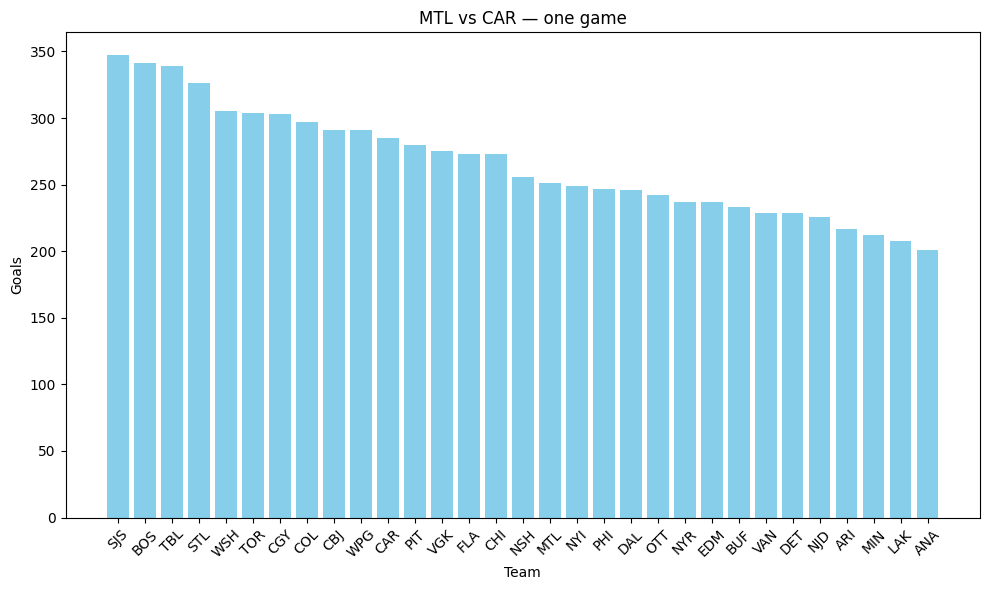

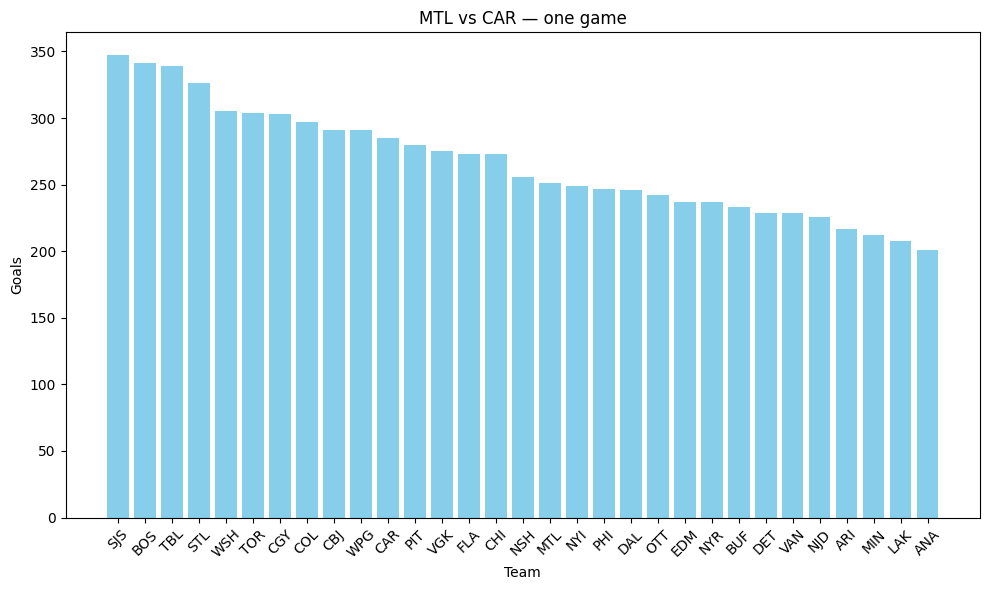

In [103]:
chart_prompt = data_context + (
    "Create a bar chart of total goals for each team: group by team and sum is_goal. "
    "Label the axes Team and Goals. Title: MTL vs CAR — one game. "
    "The output folder already exists; do not create directories."
)
chart_answer = sdf.chat(chart_prompt, output_type="plot")
chart_code = sdf.last_code_executed
if isinstance(chart_answer, str) and chart_answer.endswith(".png") and Path(chart_answer).is_file():
    display(Image(filename=chart_answer))
else:
    print(chart_answer)
print(chart_code)
display(expected[["goals"]])  # Compare these values with the bar heights.

### Bilan des requêtes

Cette cellule regroupe les résultats des trois vérifications et présente le taux de réussite après validation du graphique.

In [104]:
chart_ok = None  # Replace with True or False after inspecting the chart; an error is False.
evaluation = pd.DataFrame({
    "task": ["MTL goal count", "Team summary", "Goals-by-team chart"],
    "correct": [count_ok, table_ok, chart_ok],
})
display(evaluation)
print("Model calls, including internal repairs:", pandas_llm.calls)
if evaluation["correct"].notna().all():
    print(f"Success rate: {evaluation['correct'].astype(bool).mean():.0%}")
else:
    print("Review the chart before reporting a success rate.")

,task,correct
0,MTL goal count,False
1,Team summary,False
2,Goals-by-team chart,None


Model calls, including internal repairs: 4
Review the chart before reporting a success rate.


### 8 Questions d'évaluation

Cette cellule définit huit questions fixes pour évaluer le système, couvrant les regroupements, les pourcentages de buts, les graphiques et une question à laquelle les données ne permettent pas de répondre.

In [105]:
evaluation_questions = [
    # Strings
    ("Which shot type had the highest goal percentage in the 2018-19 season?", "string"),
    ("Which shot type had the highest goal percentage among shots taken more than 30 feet from the net in the 2019-20 season?", "string"),
    ("Which shot type was the most frequent in the 2019-20 season?", "string"),
    ("On average, how many passes were made before a goal was scored in the 2020-21 season?", "string"), # Question impossible

    # Tables
    ("How many goals did MTL and TOR each score in the 2020-21 season?", "dataframe"),
    ("Compare the goal percentages on wrist shots for MTL and TOR in the 2018-19 season.", "dataframe"),

    # Graphes
    ("Create a bar chart comparing shot events and goals for each shot type in the 2020-21 season.", "plot"),
    ("Create a graph showing goal percentage by distance from the net in the 2018-19 season, using 5-foot distance bins. Only display percentages for bins containing at least 10 shot events.", "plot"),
]

### Calcul des réponses de référence

Cette cellule calcule les réponses attendues aux 8 questions avec Pandas et les fonctions de l'équipe, afin de les comparer indépendamment aux résultats de Qwen.

In [106]:
from ift6758.visualizations.simple_viz import get_shots_and_goals, compute_goal_percent

shots_2018 = shots.loc[shots["season"] == "2018"]
shot_counts, goal_counts = get_shots_and_goals(shots_2018, "shot_type", count=True)
goal_counts = goal_counts.reindex(shot_counts.index, fill_value=0)
q1 = (100 * goal_counts / (shot_counts + goal_counts)).sort_values(ascending=False)

shots_2019_far = shots.loc[(shots["season"] == "2019") & (shots["distance"] > 30)]
shot_counts, goal_counts = get_shots_and_goals(shots_2019_far, "shot_type", count=True)
goal_counts = goal_counts.reindex(shot_counts.index, fill_value=0)
q2 = (100 * goal_counts / (shot_counts + goal_counts)).sort_values(ascending=False)

q3 = shots.loc[shots["season"] == "2019", "shot_type"].value_counts()

q4 = "Impossible à déterminer car les événements de passe ne figurent pas dans les données ordonnées"

q5 = shots.loc[(shots["season"] == "2020") & shots["team"].isin(["MTL", "TOR"])].groupby("team").agg(goals=("is_goal", "sum"))

q6 = shots.loc[(shots["season"] == "2018")
    & shots["team"].isin(["MTL", "TOR"])
    & (shots["shot_type"] == "wrist")
].groupby("team").agg(
    shots=("event_id", "size"),
    goals=("is_goal", "sum"),
)
q6["goal_pct"] = 100 * q6["goals"] / q6["shots"]

shots_2020 = shots.loc[shots["season"] == "2020"]
shot_counts, goal_counts = get_shots_and_goals(shots_2020, "shot_type", count=True)
goal_counts = goal_counts.reindex(shot_counts.index, fill_value=0)
q7 = pd.DataFrame({"shots": shot_counts + goal_counts, "goals": goal_counts})

bins = np.arange(0, 200, 5)
q8 = pd.Series(compute_goal_percent(shots_2018, bin_size=5, df_columns=bins), index=bins, name="goal_pct") # voire annexe (Amira 3)

references = [q1, q2, q3, q4, q5, q6, q7, q8]

for question, reference in zip(evaluation_questions, references):
    display(Markdown(f"**Question : {question[0]}**"))

    if isinstance(reference, pd.Series):
        display(reference.to_frame())
    else:
        display(reference)

**Question : Which shot type had the highest goal percentage in the 2018-19 season?**

,count
shot_type,
tip-in,17.088889
deflected,15.723645
backhand,11.780665
snap,10.136208
wrist,9.080033
wrap-around,6.764374
slap,6.39288


**Question : Which shot type had the highest goal percentage among shots taken more than 30 feet from the net in the 2019-20 season?**

,count
shot_type,
deflected,7.391304
snap,5.339806
slap,5.154102
tip-in,4.210526
wrist,3.786182
backhand,2.386935
wrap-around,0.0


**Question : Which shot type was the most frequent in the 2019-20 season?**

...

,shots,goals,goal_pct
team,,,
MTL,1745,149,8.538682
TOR,1677,174,10.375671


**Question : Create a bar chart comparing shot events and goals for each shot type in the 2020-21 season.**

,shots,goals
shot_type,,
wrist,32971,2997
slap,7983,561
snap,7798,812
backhand,4453,538
tip-in,2798,504
deflected,1168,182
wrap-around,559,38


**Question : Create a graph showing goal percentage by distance from the net in the 2018-19 season, using 5-foot distance bins. Only display percentages for bins containing at least 10 shot events.**

,goal_pct
0,32.421875
5,18.716508
10,16.822967
15,15.463631
20,12.528824
25,11.369319
30,8.626245
35,6.153184
40,4.647560
45,3.950574


### Exécution des questions d'évaluation

Cette cellule soumet les huit questions à PandasAI et conserve les réponses ainsi que le code généré par Qwen pour leur vérification.

2026-10-20 06:42:48 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbreviations. The distance column contains the estimated shot distance to the net in feet. Missing shot_type values must not exclude rows from overall shot counts. Use df = dfs[0] directly and filter the requested season. Do not read another file or invent unavailable information. For plot requests, generate the chart with matplotlib and save it as a PNG file before returning its path. Which shot type had the highest goal percentage in the 2018-19 season?
2026-10-20 06:42:48 [INFO] Running PandasAI with qwen-local LLM...
2026-10-20 06:42:48 [INFO] Prompt ID: 102b9a5d-33d5-49c3-86d8-e57d1026c7b7
2026-10-20 06:42:48 [INFO] Generating new code...
2026-10-20 06:42:48 [INFO] Using Prompt

StringResponse(type='string', value='The shot type with the highest goal percentage in the 2018-19 season is tip-in.')

Generated code:
 import pandas as pd
sql_query = """
SELECT 
    shot_type,
    COUNT(*) AS total_shots,
    SUM(CASE WHEN is_goal = True THEN 1 ELSE 0 END) AS goals,
    (SUM(CASE WHEN is_goal = True THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) AS goal_percentage
FROM table_233c64694146b7fb3b42a487afe4d3c9
WHERE season = '2018'
    AND event_type = 'shot-on-goal'
GROUP BY shot_type
ORDER BY goal_percentage DESC
LIMIT 1
"""
df = execute_sql_query(sql_query)
result = {'type': 'string', 'value': f"The shot type with the highest goal percentage in the 2018-19 season is {df.iloc[0]['shot_type']}."}
Appels à Qwen : 1
2026-10-20 06:43:30 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbreviations. The distance column contains the estimated shot distance to the

StringResponse(type='string', value='The shot type with the highest goal percentage among shots taken more than 30 feet from the net in the 2019-20 season is slap.')

Generated code:
 import pandas as pd
sql_query = """
SELECT 
    shot_type,
    COUNT(*) AS total_shots,
    SUM(CASE WHEN is_goal = True THEN 1 ELSE 0 END) AS goals,
    (SUM(CASE WHEN is_goal = True THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) AS goal_percentage
FROM table_233c64694146b7fb3b42a487afe4d3c9
WHERE season = '2020'
    AND event_type = 'shot-on-goal'
    AND distance > 30
GROUP BY shot_type
ORDER BY goal_percentage DESC
LIMIT 1
"""
df = execute_sql_query(sql_query)
result = {'type': 'string', 'value': f"The shot type with the highest goal percentage among shots taken more than 30 feet from the net in the 2019-20 season is {df.iloc[0]['shot_type']}."}
Appels à Qwen : 1
2026-10-20 06:43:51 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbrevi

...

Generated code:
 import pandas as pd
sql_query = """
SELECT 
    team,
    COUNT(*) AS total_wrist_shots,
    SUM(CASE WHEN is_goal = TRUE THEN 1 ELSE 0 END) AS goals_from_wrist_shots,
    (SUM(CASE WHEN is_goal = TRUE THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) AS goal_percentage
FROM table_233c64694146b7fb3b42a487afe4d3c9
WHERE season = '2018'
    AND event_type = 'wrist'
    AND team IN ('MTL', 'TOR')
GROUP BY team
ORDER BY goal_percentage DESC
"""
df = execute_sql_query(sql_query)
result = {'type': 'dataframe', 'value': df}
Appels à Qwen : 1
2026-10-20 06:45:47 [INFO] Question: This dataframe contains NHL shot-on-goal and goal events from the 2018-19, 2019-20 and 2020-21 seasons. Each row is one shot event INCLUDING goals. is_goal is Boolean. The season column contains string values: '2018', '2019' and '2020'. The team column contains NHL team abbreviations. The distance column contains the estimated shot distance to the net in feet. Missing shot_type values must not exclude rows from o

ErrorResponse(type='error', value='Unfortunately, I was not able to get your answer. Please try again.')

Generated code:
 import pandas as pd
sql_query = """
SELECT 
    shot_type,
    COUNT(*) AS total_shots,
    SUM(CASE WHEN is_goal = TRUE THEN 1 ELSE 0 END) AS goals
FROM table_233c64694146b7fb3b42a487afe4d3c9
WHERE season = '2020'
GROUP BY shot_type
ORDER BY total_shots DESC
"""
df = execute_sql_query(sql_query)
df = df.dropna(subset=['shot_type'])
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
bars = plt.bar(df['shot_type'], df['total_shots'], label='Total Shots', alpha=0.8)
plt.bar(df['shot_type'], df['goals'], label='Goals', alpha=0.8, hatch='//')
plt.title('Shot Events and Goals by Shot Type in 2020-21 Season')
plt.xlabel('Shot Type')
plt.ylabel('Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
chart_path = 'exports/charts/temp_chart_dc9a1951-1d33-4c6d-a2d0-1a5383100288.png'
plt.savefig(chart_path)
plt.close()
result = {'type': 'plot', 'value': 'exports/charts/temp_chart_dc9a1951-1d33-4c6d-a2d0-1a5383100288.png'}
Appels à Qwen : 2
2026-10-20 06:46:22 [I

ChartResponse(type='chart', value='exports/charts/temp_chart_e1427f43-6a40-499e-9531-6e95ee3b459b.png')

Generated code:
 import pandas as pd
sql_query = """
SELECT 
    FLOOR(distance / 5) * 5 AS distance_bin,
    COUNT(*) AS total_shots,
    SUM(CASE WHEN is_goal = TRUE THEN 1 ELSE 0 END) AS goals
FROM table_233c64694146b7fb3b42a487afe4d3c9
WHERE season = '2018'
GROUP BY FLOOR(distance / 5) * 5
HAVING total_shots >= 10
ORDER BY distance_bin
"""
df = execute_sql_query(sql_query)
df['goal_percentage'] = (df['goals'] / df['total_shots'] * 100).round(1).astype(str) + '%'
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
bars = plt.bar(df['distance_bin'], df['goal_percentage'], color='skyblue', edgecolor='black', alpha=0.8)
plt.title('Goal Percentage by Distance from Net (2018-19 Season)')
plt.xlabel('Distance from Net (feet)')
plt.ylabel('Goal Percentage')
plt.xticks(df['distance_bin'])
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
import os
os.makedirs('exports/charts', exist_ok=True)
chart_path = 'exports/charts/temp_chart_e1427f43-6a40-499e-9

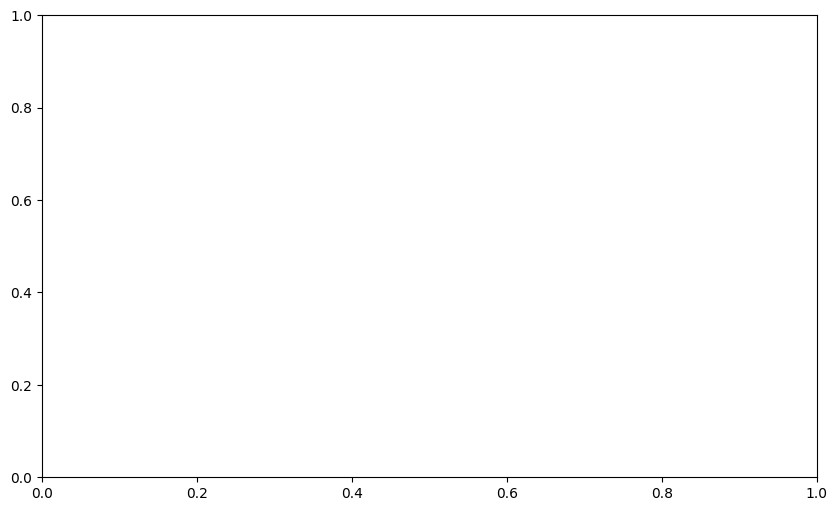

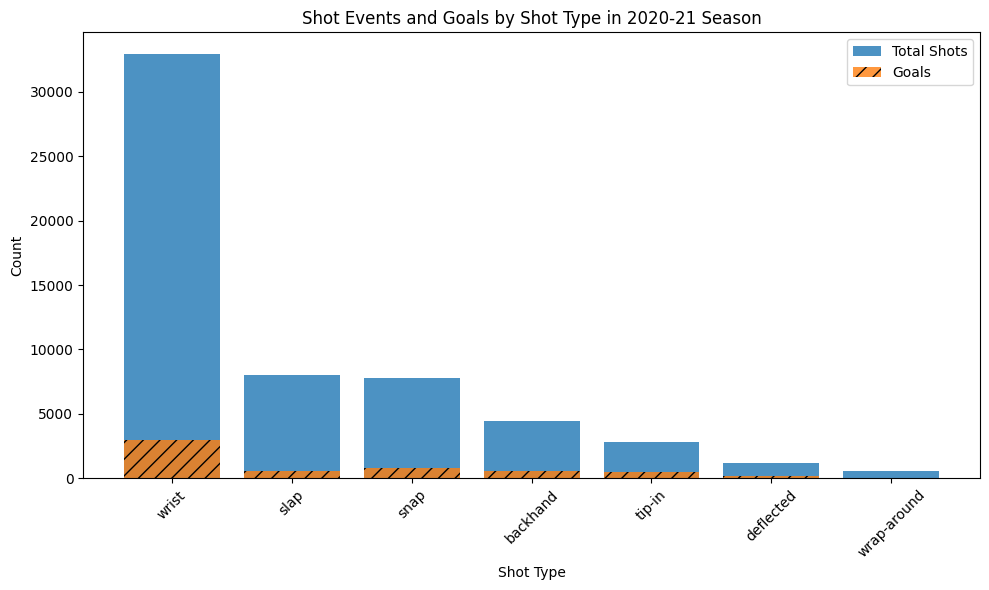

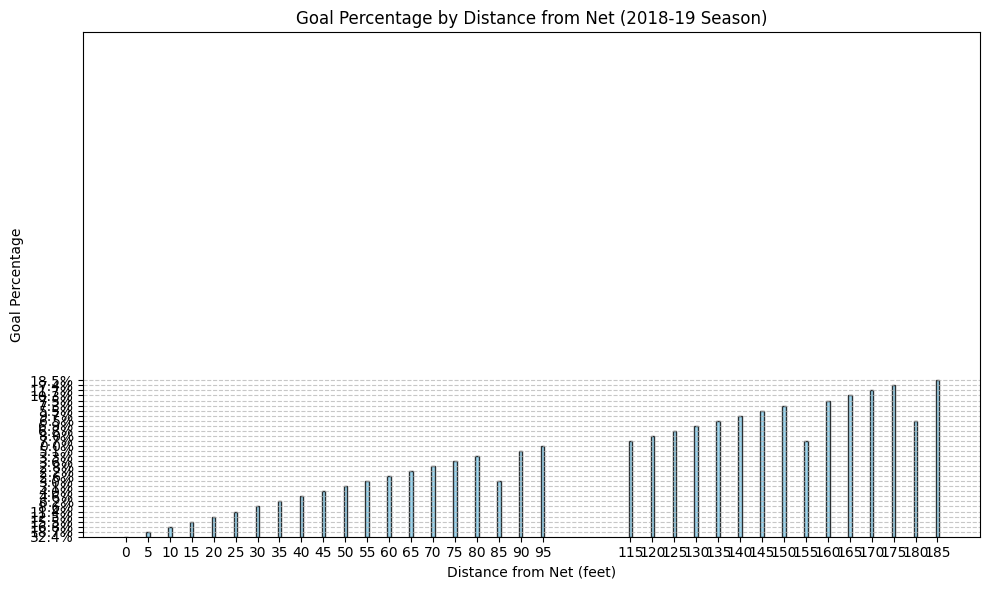

In [111]:
answers = []
codes = []
calls_per_question = []

for question, output_type in evaluation_questions:
    before = pandas_llm.calls

    try:
        answer = sdf.chat(data_context + question, output_type=output_type)
        code = sdf.last_code_executed
    except Exception as error:
        answer = error
        code = None

    answers.append(answer)
    codes.append(code)
    calls_per_question.append(pandas_llm.calls - before)

    print("\nQuestion:", question)
    display(answer)
    print("Generated code:\n", code)
    print("Appels à Qwen :", calls_per_question[-1])

### Comparaison des réponses avec les références

Cette cellule présente chaque réponse générée par Qwen avec son résultat de référence, afin de vérifier les valeurs, les regroupements et les graphiques.

In [110]:
for i, ((question, output_type), answer, reference) in enumerate(
    zip(evaluation_questions, answers, references), start=1
):
    display(Markdown(f"### Q{i} - {question}"))
    display(Markdown("**Réponse de Qwen :**"))

    if output_type == "plot" and hasattr(answer, "value"):
        chart_path = Path(answer.value)

        if chart_path.is_file():
            display(Image(filename=str(chart_path)))
        else:
            display(answer.value)
    else:
        display(answer)

    display(Markdown("**Référence pandas :**"))

    if isinstance(reference, pd.Series):
        display(reference.to_frame())
    else:
        display(reference)

### Q1 - Which shot type had the highest goal percentage in the 2018-19 season?

**Réponse de Qwen :**

StringResponse(type='string', value='The shot type with the highest goal percentage in the 2018-19 season is None with a goal percentage of 0.833.')

**Référence pandas :**

,count
shot_type,
tip-in,17.088889
deflected,15.723645
backhand,11.780665
snap,10.136208
wrist,9.080033
wrap-around,6.764374
slap,6.39288


...

### Q8 - Create a graph showing goal percentage by distance from the net in the 2018-19 season, using 5-foot distance bins. Only display percentages for bins containing at least 10 shot events.

**Réponse de Qwen :**

'Unfortunately, I was not able to get your answer. Please try again.'

**Référence pandas :**

,goal_pct
0,32.421875
5,18.716508
10,16.822967
15,15.463631
20,12.528824
25,11.369319
30,8.626245
35,6.153184
40,4.647560
45,3.950574


### Table des évaluations

Cette cellule récapitule, pour chaque question, la réussite de la première exécution, l'exactitude de la réponse finale et le nombre de nouvelles tentatives.

In [109]:
first_attempts = [
    True,   # Q1
    True,   # Q2
    True,   # Q3
    False,   # Q4
    True,   # Q5
    True,   # Q6
    False,   # Q7
    False,   # Q8
]
correct = [
    False,   # Q1
    False,   # Q2
    True,   # Q3
    True,   # Q4
    True,   # Q5
    False,   # Q6
    False,   # Q7
    False,   # Q8
]
retries = [max(0, calls - 1) for calls in calls_per_question]

evaluation = pd.DataFrame({
    "task": [question for question, _ in evaluation_questions],
    "first_attempt": first_attempts,
    "correct": correct,
    "retries": retries,
})

display(evaluation)

,task,first_attempt,correct,retries
0,Which shot type had the highest goal percentag...,True,False,0
1,Which shot type had the highest goal percentag...,True,False,0
2,Which shot type was the most frequent in the 2...,True,True,0
3,"On average, how many passes were made before a...",False,True,1
4,How many goals did MTL and TOR each score in t...,True,True,0
5,Compare the goal percentages on wrist shots fo...,True,False,0
6,Create a bar chart comparing shot events and g...,False,False,1
7,Create a graph showing goal percentage by dist...,False,False,1
